In [1]:
import numpy as np
import matplotlib.pyplot as plt
# from scipy.interpolate import interp1d
# from matplotlib.colors import Normalize
from skimage import transform

import matplotlib as mpl
plt.style.use('../../src/bip.mplstyle')

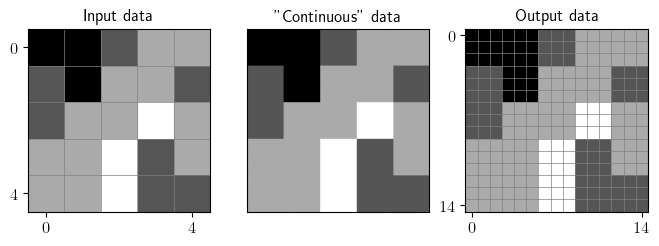

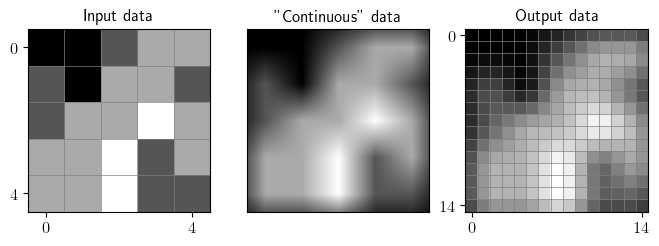

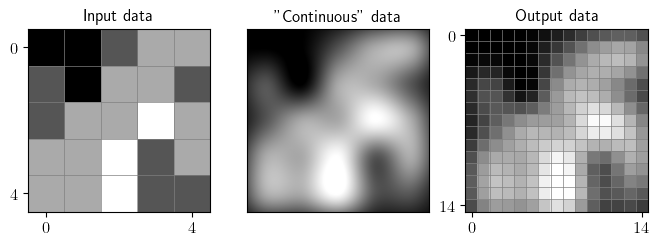

In [2]:
# Input image
img = np.array([ [0,0,1,2,2], [1,0,2,2,1], [1,2,2,3,2], [2,2,3,1,2], [2,2,3,1,1] ])
N = len(img)

# Interpolation methods
methods = [
    (0, "nearest"),
    (1, "bilinear"),
    (3, "bicubic")
]

# Transformation
scale = 1/3
rotation = 0
translation = (-.5,-.5)
tform = transform.SimilarityTransform( scale=scale, rotation=rotation, translation=translation )

# Transformatin for the continuous version
scale_continuous = 1/70
cform = transform.SimilarityTransform( scale=scale_continuous, rotation=rotation, translation=translation )

# Display and save
for order, kind in methods:

    # Prepare display
    fig, axs = plt.subplots(1, 3, figsize=(8,3))

    # Input image
    axs[0].imshow(img, 'gray')
    axs[0].set_xticks([0, N-1])
    axs[0].set_yticks([0, N-1])
    for n in range(1,N):
        axs[0].axvline(n-.5, color='gray', linewidth=.5)
        axs[0].axhline(n-.5, color='gray', linewidth=.5)
    axs[0].set_title("Input data", size=12)

    # "Continuous"
    interpolated = transform.warp(img, cform, order=order, output_shape=(N//scale_continuous,N//scale_continuous))
    axs[1].imshow(interpolated, "gray")
    axs[1].set_xticks([], labels=[])
    axs[1].set_yticks([], labels=[])
    axs[1].set_title('"Continuous" data', size=12)

    # Interpolation
    interpolated = transform.warp(img, tform, order=order, output_shape=(N//scale,N//scale))
    axs[2].imshow(interpolated, "gray")
    axs[2].set_xticks([0, N//scale-1])
    axs[2].set_yticks([0, N//scale-1])
    for n in range(1,int(N//scale)):
        axs[2].axvline(n-.5, color='gray', linewidth=.5)
        axs[2].axhline(n-.5, color='gray', linewidth=.5)
    axs[2].set_title("Output data", size=12)

    plt.savefig(f"interp-{kind}-2d.svg", bbox_inches='tight')